python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --eval_method trained --if_log True

python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --eval_method estimated --if_log True

python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --eval_method greedy --if_log True

python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --eval_method random --if_log True

python3 Extension_BM/baseline_train.py 
python Extension_BM/baseline_train --N_UTs 2 

/bin/python /work/Extension_BM/baseline_train.py --N_UTs 3 --Nt 16 --timesteps 800000

/bin/python /work/Extension_BM/baseline_train.py --N_UTs 2 --Nt 32 --timesteps 800000

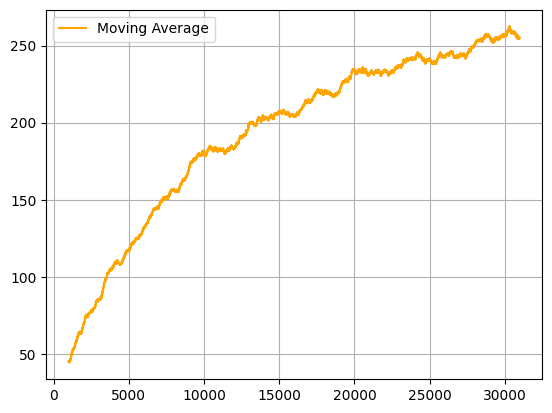

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
def append_csv(source_file, target_file):
    source_data = pd.read_csv(source_file, skiprows = 0)
    target_data = pd.read_csv(target_file, skiprows = 1)

    combined_data = pd.concat([source_data, target_data])
    combined_data.to_csv(target_file, index=False)

# Example usage
# source_file = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_rSE/monitor_1.csv'
# target_file = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_rSE/monitor.csv'
# append_csv(source_file, target_file)

monitor_file = 'RL_mimo_ofdm/PPO_3ue16Nt_logEstTh_beamAct/' + "monitor.csv"

monitor_data = pd.read_csv(monitor_file, skiprows=1)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
fig, ax = plt.subplots()
ax.plot(moving_average, label='Moving Average', color='orange')
ax.legend()
ax.grid()

plt.show()

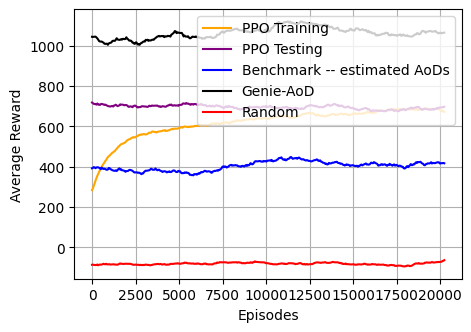

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
log_dir = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_rSE/'
monitor_file = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_rSE/' + "monitor.csv"

monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()

fd_trained = log_dir +'trained/'
trained_reward = pd.read_csv(fd_trained + 'reward.csv', skiprows=0)
tr = trained_reward['Reward'].rolling(window = 100).mean()

fd_genie = log_dir +'greedy/'
genie_reward = pd.read_csv(fd_genie + 'reward.csv', skiprows=0)
gr = genie_reward['Reward'].rolling(window = 100).mean()


fd_estimated = log_dir +'estimated/'
benchmark_reward = pd.read_csv(fd_estimated + 'reward.csv', skiprows=0)
br = benchmark_reward['Reward'].rolling(window = 100).mean()
br_length = len(br.dropna())

fd_random = log_dir +'random/'
random_reward = pd.read_csv(fd_random + 'reward.csv', skiprows=0)
rr = random_reward['Reward'].rolling(window = 100).mean()

selected_values = moving_average[::len(moving_average)//br_length][:(br_length)]


fig, ax = plt.subplots()
fig.set_size_inches(5, 3.5)
ax.plot(np.linspace(0, len(moving_average), br_length), selected_values.dropna(), label='PPO Training', color='orange')
# ax.plot(np.linspace(0, len(moving_average_reusebeams), br_length), selected_values_reusebeams.dropna(), label='PPO_128_new_statespace', color='green')
ax.plot(np.linspace(0, len(moving_average), br_length), tr.dropna(), label='PPO Testing', color='purple')
ax.plot(np.linspace(0, len(moving_average), br_length), br.dropna(), label='Benchmark -- estimated AoDs', color='blue')
ax.plot(np.linspace(0, len(moving_average), br_length), gr.dropna(), label='Genie-AoD', color='black')
ax.plot(np.linspace(0, len(moving_average), br_length), rr.dropna(), label='Random', color='red')
# ax.plot(np.linspace(0, len(moving_average), br_length), tr2.dropna(), label='PPO_128_new_statespace Test Test', color='red')

ax.legend(loc='upper right')
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')

plt.show()

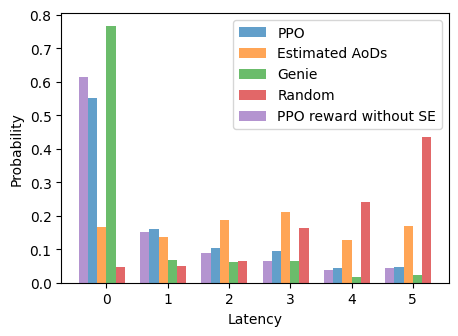

In [38]:
import matplotlib.pyplot as plt
import itertools
import pandas as pd

def load_latency(log_dir, filename):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    data1 = list(itertools.chain(*data.values))
    data2 = [x for x in data1 if x != -1]
    return data2

latency_trained = load_latency(fd_trained, 'latency.csv')
latency_benchmark = load_latency(fd_estimated, 'latency.csv')

latency_genie = load_latency(fd_genie , 'latency.csv')
latency_r = load_latency(fd_random , 'latency.csv')

latency_trained_woSE = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/trained/', 'latency.csv')
#
figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax2 = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax2.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark, bins_benchmark, patches_benchmark = ax2.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie, bins_genie, patches_genie = ax2.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie')
counts_random, bins_random, patches_random = ax2.hist(latency_r, bins=range(7), density=True, alpha=0.7, label='Random')
counts_trainedwo, bins_trainedwo, pathes_trainedwo = ax.hist(latency_trained_woSE, bins=range(7), density=True, alpha=0.7, label='PPO')

bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])
barwidth = 0.15
ax2.cla()  # Clear the previous plot
ax2.bar(bin_centers - barwidth*3/2, counts_trained, width=barwidth, align='center', alpha=0.7, label='PPO')
ax2.bar(bin_centers - barwidth/2, counts_benchmark, width=barwidth, align='center', alpha=0.7, label='Estimated AoDs')
ax2.bar(bin_centers + barwidth/2, counts_genie, width=barwidth, align='center', alpha=0.7, label='Genie')
ax2.bar(bin_centers + barwidth*3/2, counts_random, width=barwidth, align='center', alpha=0.7, label='Random')
ax2.bar(bin_centers - barwidth*5/2, counts_trainedwo, width=barwidth, align='center', alpha=0.7, label='PPO reward without SE')

ax2.set_xticks(bin_centers)

ax2.set_xticks(bin_centers)
ax2.set_xticklabels(range(6))
ax2.set_xlabel('Latency')
ax2.set_ylabel('Probability')
ax2.legend()

---

### Sensing

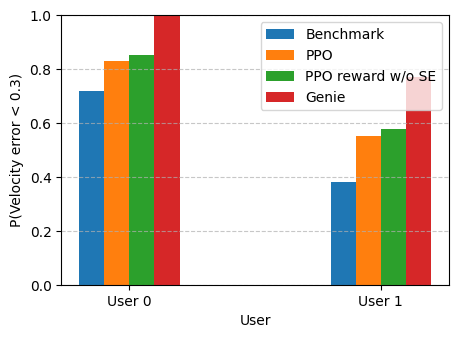

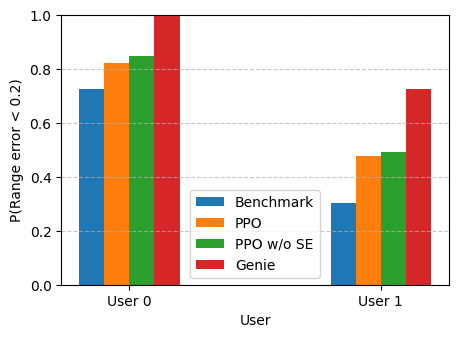

In [39]:
er_t = pd.read_csv(fd_trained + 'nmseR_allsteps.csv', skiprows=1)
er_b = pd.read_csv(fd_estimated + 'nmseR_allsteps.csv', skiprows=1)
# er_r = pd.read_csv(fd_random + 'nmseR_allsteps.csv', skiprows=1)
er_g = pd.read_csv(fd_genie + 'nmseR_allsteps.csv', skiprows=1)
er_t2 = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/trained/nmseR_allsteps.csv', skiprows=1)

er_benchmark = np.array(er_b)
er_trained = np.array(er_t)
er_genie = np.array(er_g)
er_trained_woSE = np.array(er_t2)

ev_t = pd.read_csv(fd_trained + 'nmseV_allsteps.csv', skiprows=1)
ev_b = pd.read_csv(fd_estimated + 'nmseV_allsteps.csv', skiprows=1)
ev_g = pd.read_csv(fd_genie + 'nmseV_allsteps.csv', skiprows=1)
# ev_r = pd.read_csv(fd_random + 'nmseV_allsteps.csv', skiprows=1)

ev_t2 = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/trained/nmseV_allsteps.csv', skiprows=1)

ev_benchmark = np.array(ev_b)
ev_trained = np.array(ev_t)
ev_genie = np.array(ev_g)
ev_trained_woSE = np.array(ev_t2)

# figure_handle = plt.figure()
# ax4 = figure_handle.add_subplot()

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']
linestyles = {'Estimated AoD': '--', 'PPO': '-', 'Genie': ':'}
labels = ['User 0', 'User 1']


def prob_error_below_threshold(data, threshold=0.2):
    return [(data[:, idx] < threshold).mean() for idx in range(data.shape[1])]


th_prob = 0.3
prob_benchmark = prob_error_below_threshold(ev_benchmark, th_prob)
prob_trained0 = prob_error_below_threshold(ev_trained, th_prob)
prob_genie = prob_error_below_threshold(ev_genie, th_prob)
prob_trained_woSE = prob_error_below_threshold(ev_trained_woSE, th_prob)
x = np.arange(len(labels))
width = 0.1

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - 3*width/2, prob_benchmark, width, label='Benchmark')
ax.bar(x - width/2 , prob_trained0, width, label='PPO')
ax.bar(x + width/2, prob_trained_woSE, width, label='PPO reward w/o SE')
ax.bar(x + 3*width/2, prob_genie, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(Velocity error < 0.3)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Calculate for range estimation error
prob_range_trained = prob_error_below_threshold(er_trained, th_prob)
prob_range_benchmark = prob_error_below_threshold(er_benchmark, th_prob)
prob_range_genie = prob_error_below_threshold(er_genie, th_prob)
prob_range_trained_woSE = prob_error_below_threshold(er_trained_woSE, th_prob)

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - 3*width/2, prob_range_benchmark, width, label='Benchmark')
ax.bar(x - width/2, prob_range_trained, width, label='PPO')
ax.bar(x + width/2, prob_range_trained_woSE, width, label='PPO w/o SE')
ax.bar(x + 3*width/2, prob_range_genie, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(Range error < 0.2)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()